# TP2 : enrichissement du corpus CAMille, Le Soir en 1960

Ce notebook rassemble mes analyses des 100 pages du Soir de 1960. J'y cherche les mots-clés de l'année, je construis un nuage de mots, je repère les personnes, lieux et organisations les plus cités, puis j'étudie le sentiment exprimé dans dix phrases.

In [1]:
import os
import re
from collections import Counter, defaultdict

import yake
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud
from IPython.display import Image
import spacy
import pandas as pd
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

c:\Users\DERRICK\tac\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Choix de l'année et des fichiers

In [4]:
year = 1960
txt_path = "../../data/txt/"
temp_path = "../../data/tmp"

files = sorted([f for f in os.listdir(txt_path) if f.endswith('.txt') and f"_{year}-" in f])
len(files)

100

## 1. Les mots-clés de l'année avec YAKE

YAKE repère les expressions importantes de chaque page. Je garde celles de deux mots, comme « Congo belge » ou « Nations Unies », puis je regarde lesquelles reviennent le plus souvent au fil de l'année.

In [5]:
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)

# Mots-clés de deux mots de chaque page de l'année
for f in files:
    with open(os.path.join(txt_path, f), 'r', encoding='utf-8') as fh:
        text = fh.read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB838_1960-01-10_01-00018.txt mentions these keywords: Agence Rossel, l’Agence Rossel, Ecrire Agence, Faire offre, Rossel num, IMPORTANTE SOCIETE, Importante firme, BRUXELLES CHERCHE, Importante société, Firme Importante, curriculum vitae, offre manuscrite, vltae Agence...
KB_JB838_1960-01-12_01-00011.txt mentions these keywords: Van den, Van der, classements officiels, Coq Anglais, Van Houtte, Country Club, Léopold Club, Van Blesebroeck, Astrld Club, Van Belle, Baudouin Club...
KB_JB838_1960-01-13_01-00009.txt mentions these keywords: VAN LOOY, Van Stcenbergen, Rik Van, DIVISION III, Fort Jaco, Grand Prix, grand temps, Dimanche division, dimanche dernier...
KB_JB838_1960-01-21_01-00014.txt mentions these keywords: chemise lavée, CHEMISES LAVÉES, Office Propriétaires, Propriétaires Tél, WATERLOO TéL, maison rapport, belle maison, PRIX TARIF, francs Office, bonne maison...
KB_JB838_1960-01-22_01-00015.txt mentions these keywords: LOUER App, Pastilles Antibiotiques, FER FORGE, spac. a

In [6]:
# Les expressions qui reviennent dans le plus grand nombre de pages
year_keywords = Counter()
for f in files:
    with open(os.path.join(txt_path, f), 'r', encoding='utf-8') as fh:
        text = fh.read()
    for kw, score in kw_extractor.extract_keywords(text):
        if len(kw.split()) == 2:
            year_keywords[kw] += 1

year_keywords.most_common(30)

[('Agence Rossel', 17),
 ('Ecrire Agence', 11),
 ('Rossel num', 9),
 ('l’Agence Rossel', 6),
 ('Faire offre', 6),
 ('Congo belge', 5),
 ('New York', 5),
 ('demeurant rue', 5),
 ('Bruxelles Tél', 5),
 ('curriculum vitae', 4),
 ('Van den', 4),
 ('Rik Van', 4),
 ('Grand Prix', 4),
 ('JOURNAL QUOTIDIEN', 4),
 ('habitant rue', 4),
 ('Bruxelles dem', 4),
 ('Van Looy', 4),
 ('Nations Unies', 4),
 ('offre manuscrite', 3),
 ('DIVISION III', 3),
 ('Propriétaires Tél', 3),
 ('rue Van', 3),
 ('Opel Rek', 3),
 ('SOIR MERCREDI', 3),
 ('d’une fracture', 3),
 ('Dem. fem', 3),
 ('l’AGENCE ROSSEL', 3),
 ('domicilié rue', 3),
 ('lundi matin', 3),
 ('gouvernement belge', 3)]

## 2. Le nuage de mots de 1960

Je rassemble le texte des 100 pages, je retire les mots qui n'apportent rien, puis j'affiche les mots les plus fréquents. La liste des mots à retirer s'est construite en trois étapes, en regardant à chaque fois ce qui encombrait encore le nuage.

In [10]:
nltk.download('stopwords')

# Liste de départ : mots vides de NLTK et mots ajoutés dans le cours
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]

# Itération 1 (1960) : vocabulaire et abréviations des petites annonces
sw += ["rue", "tél", "téléph", "app", "ecr", "écrire", "ecrire", "prés", "brux",
       "trav", "enf", "mod", "fem", "culs", "conf", "agence", "demande", "offre",
       "cherche", "présenter", "vente", "avenue", "mme", "bon", "bonne", "très",
       "prix", "vis", "soir"]

# Itération 2 (1960) : dates, durées et mots courants
sw += ["ans", "mois", "jours", "jour", "heures", "temps", "année", "matin", "midi",
       "lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche",
       "janvier", "février", "mars", "avril", "mai", "juin", "juillet", "août",
       "septembre", "octobre", "novembre", "décembre", "avant", "peu", "toute",
       "quelques", "leurs", "vers", "devant", "déjà", "toujours", "etc", "chez",
       "celui", "alors", "fois", "également", "quatre", "plusieurs", "près", "lieu",
       "suite", "fin", "part", "partie", "place", "grand", "grande", "premier",
       "première", "dernier", "nouveau", "petit", "gros", "mal", "cours", "libre",
       "service"]

# Itération 3 (1960) : abréviations d'annonces encore présentes et mots vides restants
sw += ["réf", "mat", "rem", "gar", "bat", "bur", "bel", "mén", "pers", "louer",
       "dactylo", "bilingue", "firme", "dame", "importante", "ceux", "vue", "effet",
       "heure", "semaine", "demi", "neuf", "rien", "jamais", "ailleurs", "car",
       "point", "moment"]

sw = set(sw)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\DERRICK\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [11]:
# Rassembler le texte des 100 pages dans un fichier temporaire
content_list = []
for f in files:
    with open(os.path.join(txt_path, f), 'r', encoding='utf-8') as fh:
        content_list.append(fh.read())

if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as fh:
    fh.write(' '.join(content_list))

In [12]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    with open(output_path, "w", encoding='utf-8') as output:
        with open(input_path, 'r', encoding='utf-8') as f:
            text = f.read()
            words = nltk.wordpunct_tokenize(text)
            kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
            kept_string = " ".join(kept)
            output.write(kept_string)
    return f'Output has been written in {output_path}!'

clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1960_clean.txt!'

In [13]:
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as fh:
    after = fh.read()

frequencies = Counter(after.split())
print(frequencies.most_common(50))

[('BRUXELLES', 1112), ('MAISON', 357), ('BELGIQUE', 346), ('BELGE', 333), ('CONGO', 294), ('FRANCS', 288), ('PAYS', 277), ('ANVERS', 270), ('JEUNE', 264), ('JEAN', 258), ('TRAVAIL', 251), ('SAINT', 247), ('ÉQUIPE', 223), ('MINISTRE', 217), ('SITUATION', 216), ('FRANCE', 215), ('ÉTAT', 212), ('BELGES', 210), ('CENTRE', 208), ('PARIS', 207), ('GÉNÉRAL', 195), ('TOUR', 194), ('FRANÇAIS', 193), ('HOMME', 193), ('GOUVERNEMENT', 191), ('ENFANTS', 187), ('DIVISION', 186), ('PRÉSIDENT', 186), ('LOUISE', 175), ('FEMME', 175), ('LOI', 175), ('ORDRE', 173), ('VIE', 173), ('BUREAU', 173), ('SOCIÉTÉ', 170), ('VOITURE', 169), ('LIÈGE', 169), ('HOMMES', 165), ('MARCHÉ', 164), ('CONSEIL', 162), ('MONDE', 162), ('CHAUSSÉE', 159), ('MILLIONS', 156), ('NAMUR', 155), ('NOUVELLE', 155), ('RAPPORT', 152), ('DÉBUT', 151), ('COUR', 150), ('NORD', 149), ('PIERRE', 146)]


Ce nuage est le même que celui de s2_wordcloud.ipynb càd mêmes mots, mêmes tailles. Seule la position des mots change, car elle est tirée au hasard à chaque génération. L'image utilisée dans le rapport est wordcloud_1960.png.

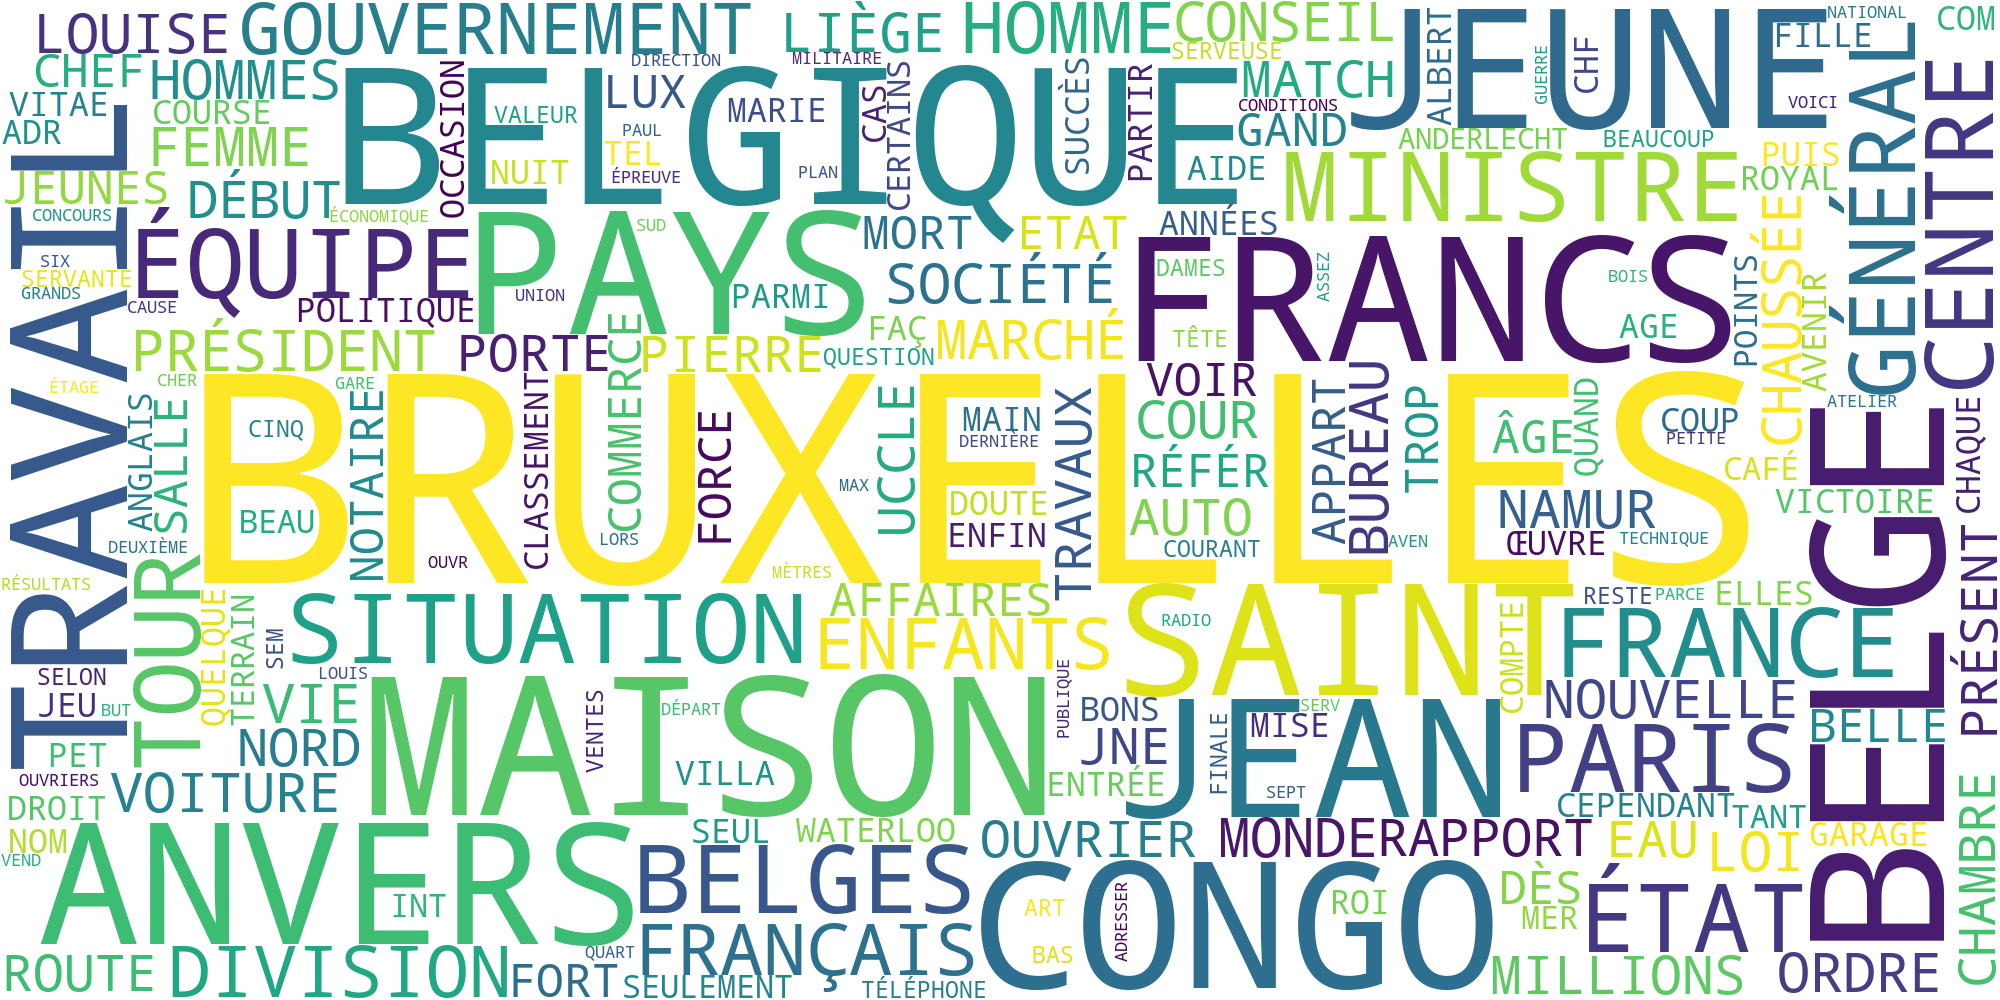

In [14]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))